# bcpnm tutorial 2: new domains, custom rules, inference and the Blume–Capel model

This notebook shows how to (1) start a model in a new domain from the configuration
template, (2) write a custom rule, (3) work with ternary Blume–Capel models and their
hysteresis, and (4) fit a model to time-series data and evaluate it on held-out data.

In [1]:
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import bcpnm as bc
from bcpnm import visualization as viz

# locate the repository root whether the notebook runs from examples/notebooks or the root
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "examples").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
EX = ROOT / "examples"
print("bcpnm", bc.__version__)

bcpnm 0.1.0


## 1. A new domain from the template: burnout

`examples/00_template_burnout.yaml` is an annotated template (Appendix B.1 of the paper).
We load it and ask how the attractor landscape depends on workload.

In [2]:
burn, cfg = bc.load_model(EX / "00_template_burnout.yaml")
print(burn.summary())
print(bc.threshold_ties(burn))
for level, w in (("low", 0), ("moderate", 1), ("high", 2)):
    res = bc.find_attractors(bc.Clamp("Workload", w).apply(burn), scheme="asynchronous")
    print(f"workload {level}:", [(" ".join(str(int(v)) for v in a.states[0]), round(a.basin_fraction, 3)) for a in res])

PNMGraph 'burnout_template': 6 nodes, 13 directed edges, 486 configurations
  Workload       states=(0, 1, 2)  rule=ClampRule()
  Exhaustion     states=(0, 1, 2)  rule=ThresholdRule(Workload, Exhaustion, Recovery)
  Recovery       states=(0, 1, 2)  rule=ThresholdRule(Workload, Exhaustion, Recovery)
  Cynicism       states=(0, 1, 2)  rule=ThresholdRule(Exhaustion, Cynicism, Efficacy)
  Efficacy       states=(0, 1, 2)  rule=CaseRule(Exhaustion, Cynicism)
  Turnover       states=(0, 1)  rule=BooleanRule(Exhaustion, Cynicism)


         node  configurations  ties
0  Exhaustion              27     0
1    Recovery              27     0
2    Cynicism              27     0
workload low: [('0 0 2 1 1 0', 0.444), ('0 0 2 0 2 0', 0.033)]
workload moderate: [('1 2 0 2 0 1', 0.148), ('1 0 2 1 1 0', 0.033), ('1 0 2 0 2 0', 0.016), ('1 1 1 1 1 0', 0.016), ('1 1 1 2 1 0', 0.008)]
workload high: [('2 2 0 2 0 1', 1.0)]


Does protecting recovery (for example, a no-email-after-hours policy) prevent burnout under
moderate workload? We clamp `Recovery` at high and compare attractors.

In [3]:
moderate = bc.Clamp("Workload", 1).apply(burn)
base = bc.find_attractors(moderate)
protected = bc.find_attractors(bc.Clamp("Recovery", 2).apply(moderate))
bc.compare_attractors(base, protected)

,attractor,before,after,change
0,1 2 0 2 0 1,0.370370,0.000000,-0.370370
1,1 1 1 1 1 0,0.172840,0.000000,-0.172840
2,1 0 2 1 1 0,0.131687,0.880658,0.748971
3,1 1 1 2 1 0,0.123457,0.000000,-0.123457
4,1 0 1 1 1 0 | 1 1 2 1 1 0,0.098765,0.000000,-0.098765
5,1 0 2 0 2 0,0.090535,0.119342,0.028807
6,1 0 1 0 1 0 | 1 1 2 0 2 0,0.012346,0.000000,-0.012346


## 2. A custom rule

Any subclass of `bc.Rule` that implements `next_value()` (deterministic) or `probs()`
(stochastic) works with every analysis. Here: a person moves to a position only if at least
`k` others hold it and outnumber the opposite camp.

In [4]:
class InertialMajority(bc.Rule):
    kind = "custom"
    def __init__(self, inputs, k=2):
        super().__init__(inputs)
        self.k = k
    def next_value(self, parents, current, values):
        pos, neg = (parents == 1).sum(axis=1), (parents == -1).sum(axis=1)
        out = np.asarray(current, dtype=float).copy()
        out[(pos >= self.k) & (pos > neg)] = 1
        out[(neg >= self.k) & (neg > pos)] = -1
        return out

committee = bc.PNMGraph("committee")
names = ["Ana", "Ben", "Cyd", "Dee"]
for n in names:
    committee.add_node(n, bc.StateSpace.ternary(("oppose", "abstain", "support")))
for n in names:
    committee.set_rule(n, InertialMajority([o for o in names if o != n], k=2))
bc.find_attractors(committee, scheme="asynchronous").table().head()

,attractor,label,kind,length,basin,basin_fraction,weak_basin,state
0,0,,fixed point,1,27,0.3333,33,-1 -1 -1 -1
1,1,,fixed point,1,27,0.3333,33,+1 +1 +1 +1
2,2,,fixed point,1,1,0.0123,1,-1 0 0 0
3,3,,fixed point,1,1,0.0123,1,-1 0 0 +1
4,4,,fixed point,1,1,0.0123,1,-1 0 +1 0


## 3. The equilibrium Blume–Capel model

States −1, 0, +1; the zero–zero term Λ makes silence self-reinforcing. Asynchronous
simulation of `model.to_graph()` is Gibbs sampling, so the exact Boltzmann distribution
and the Markov chain agree.

In [5]:
K = 0.6 * (np.ones((3, 3)) - np.eye(3))
for lam in (0.0, 0.8):
    m = bc.BlumeCapelModel(["A", "B", "C"], K, lam * (np.ones((3, 3)) - np.eye(3)), delta=0.3)
    X, p = m.exact()
    st = bc.stationary_distribution(m.to_graph())
    print(f"Lambda={lam}: P(all silent) exact {p[(X == 0).all(1)].sum():.3f}, "
          f"Markov chain {st.prob(lambda Y: (Y == 0).all(1)):.3f}")

Lambda=0.0: P(all silent) exact 0.051, Markov chain 0.051
Lambda=0.8: P(all silent) exact 0.315, Markov chain 0.315


jumps (rising, falling): (-1.6400000000000001, -1.98)


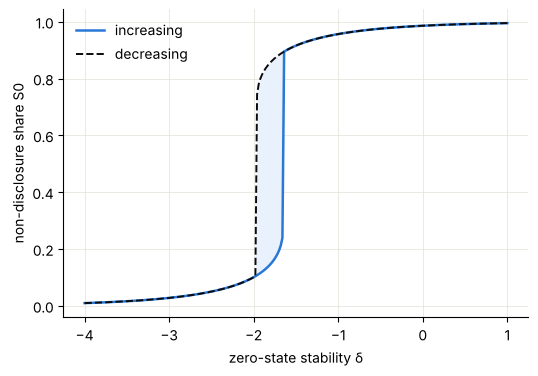

In [6]:
sweep = bc.continuation("delta", np.linspace(-4, 1, 251), beta=1.0, J=0.5, Lam=5.0, delta=0.0)
print("jumps (rising, falling):", sweep.jumps(1))
viz.plot_hysteresis(sweep, column=1, xlabel="zero-state stability δ");

## 4. Fitting a directed model to time series

We simulate panel data from a known directed network, fit the directed Blume–Capel rule by
penalized maximum likelihood, check parameter recovery, and compare held-out log scores.

In [7]:
W = {"A": {"B": 0.25}, "B": {"A": 1.15}, "C": {"B": 0.95}, "D": {"C": 0.30}, "E": {"B": 0.18}}
dg = bc.PNMGraph("directed_five")
for n in "ABCDE":
    dg.add_node(n, bc.StateSpace.ternary())
for n in "ABCDE":
    dg.set_rule(n, bc.SoftmaxRule(W[n], {k: 0.4 for k in W[n]}, h=-0.15, delta=0.3, rho=0.6, beta=1.5))
train = bc.simulate(dg, steps=40, runs=150, scheme="synchronous", seed=301)
test = bc.simulate(dg, steps=40, runs=150, scheme="synchronous", seed=302)
fit = bc.fit_transition_model(train.states, dg.names)
print("held-out log score: true", round(bc.log_score(dg, test.states), 3),
      "| fitted", round(bc.log_score(fit.to_graph(), test.states), 3))
np.round(fit.W, 2)

held-out log score: true -0.806 | fitted -0.807


array([[ 0.  ,  0.34,  0.01, -0.03,  0.01],
       [ 1.65,  0.  ,  0.01, -0.01, -0.01],
       [-0.04,  1.46,  0.  , -0.01,  0.  ],
       [-0.05,  0.03,  0.45,  0.  ,  0.03],
       [ 0.02,  0.26,  0.  , -0.  ,  0.  ]])

Because β is fixed at 1 during estimation, the estimates are on the scale β·w: with β = 1.5,
the influence of A on B (1.15) is estimated near 1.5 × 1.15 ≈ 1.7.

In [8]:
true_W = np.array([[W[t].get(s_, 0.0) for s_ in dg.names] for t in dg.names])
bc.parameter_recovery({"W": 1.5 * true_W}, {"W": fit.W})

,parameter,n,correlation,rmse,sign_agreement
0,W,25,0.998,0.025,1.0


**Exercises.** (1) Halve the number of training runs: how do recovery and the log score
change? (2) Fit with `lam=False` and compare. (3) Write a configuration file for a domain
of your own (trauma, addiction, family dynamics) by copying the template.